# Phase 3 & 4

## upload and unzip dataset

In [3]:
!unzip all_input_outputs_to_model.zip

Archive:  all_input_outputs_to_model.zip
   creating: all_input_outputs_to_model/
  inflating: all_input_outputs_to_model/0000_json_1_phase_2.json  
  inflating: all_input_outputs_to_model/0000_json_2_phase_2.json  
  inflating: all_input_outputs_to_model/0000_json_3_phase_2.json  
  inflating: all_input_outputs_to_model/0000_json_4_phase_2.json  
  inflating: all_input_outputs_to_model/0000_json_5_phase_2.json  
  inflating: all_input_outputs_to_model/0000_json_6_phase_2.json  
  inflating: all_input_outputs_to_model/0000_json_7_phase_2.json  
  inflating: all_input_outputs_to_model/0000_json_8_phase_2.json  


In [4]:
%ls all_input_outputs_to_model/

0000_json_1_phase_2.json  0000_json_4_phase_2.json  0000_json_7_phase_2.json
0000_json_2_phase_2.json  0000_json_5_phase_2.json  0000_json_8_phase_2.json
0000_json_3_phase_2.json  0000_json_6_phase_2.json


##  1. Install dependencies

In [1]:
!pip install torch transformers datasets sentence-transformers scikit-learn -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 65.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 46.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 38.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 14.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 9.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 188.7/188.7 MB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 102.4 MB/s eta 0:00:00


## 2. Load and preprocess your dataset

### get familiar with dataset, perform analysis and find the good MAX_LENGTH

In [ ]:
import json
import os
from pathlib import Path

data_dir = Path("all_input_outputs_to_model")
texts, questions = [], []

for file in data_dir.glob("*.json"):
    with open(file, "r", encoding="utf-8") as f:
        data = json.load(f)
        for item in data:
            text = item["textual_content_response"]
            texts.append(text)
            for qa in item["question_and_answer_response"]["questions_and_answers"]:
                questions.append((qa["question"], text))  # (question, related_text)

len(questions), len(texts)

(52036, 10410)

In [ ]:
import pandas as pd

# Step 1: Convert the array of tuples into a pandas DataFrame
df = pd.DataFrame(questions, columns=['question', 'related_text'])
df.head(10)

,question,related_text
0,ابواسحاق جویباری چه شغل‌هایی داشت؟,ابواسحاق جویباری مردی زرگر و شاعر بود. او که ب...
1,ابواسحاق جویباری در کدام دوره تاریخی می‌زیسته ...,ابواسحاق جویباری مردی زرگر و شاعر بود. او که ب...
2,ابواسحاق جویباری در کدام شهر متولد شده است؟,ابواسحاق جویباری مردی زرگر و شاعر بود. او که ب...
3,مقبره ابواسحاق جویباری در کجا قرار دارد؟,ابواسحاق جویباری مردی زرگر و شاعر بود. او که ب...
4,ابواسحاق جویباری در چه زمینه‌ای از پیشگامان بو...,ابواسحاق جویباری مردی زرگر و شاعر بود. او که ب...
5,ابوحفص سغدی در چه سده‌ای می‌زیست؟,ابوحفص سغدی، که با نام‌های غضایری و ابوحفض نیز...
6,ابوحفص سغدی در کدام منطقه متولد شد؟,ابوحفص سغدی، که با نام‌های غضایری و ابوحفض نیز...
7,ابوحفص سغدی به عنوان یکی از پیشگامان چه چیزی ش...,ابوحفص سغدی، که با نام‌های غضایری و ابوحفض نیز...
8,کدام ساز به ابوحفص سغدی نسبت داده می‌شود؟,ابوحفص سغدی، که با نام‌های غضایری و ابوحفض نیز...
9,نام‌های دیگر ابوحفص سغدی چه بود؟,ابوحفص سغدی، که با نام‌های غضایری و ابوحفض نیز...


In [ ]:
# Find the maximum and average lengths for each column
max_question_length = df['question'].str.len().max()
avg_question_length = df['question'].str.len().mean()

max_related_text_length = df['related_text'].str.len().max()
avg_related_text_length = df['related_text'].str.len().mean()

# Print the results
print(f"Maximum length of 'question': {max_question_length}")
print(f"Average length of 'question': {avg_question_length:.2f}")

print(f"Maximum length of 'related_text': {max_related_text_length}")
print(f"Average length of 'related_text': {avg_related_text_length:.2f}")

Maximum length of 'question': 153
Average length of 'question': 47.75
Maximum length of 'related_text': 5852
Average length of 'related_text': 451.59


because of the much data we can filter with less than 512

In [ ]:
df.count()

,0
question,52036
related_text,52036


In [ ]:
# Step 2: Save the DataFrame to a file (e.g., CSV, JSON)
file_path = 'questions_texts_dataset_csv.csv'  # Specify the file path
df.to_csv(file_path, index=False, encoding='utf-8')  # Save without the index column
print("DataFrame saved successfully as CSV.")

file_path = 'questions_texts_dataset_json.json'  # Specify the file path
df.to_json(file_path, orient='records', force_ascii=False, indent=4)  # Save as JSON
print("DataFrame saved successfully as JSON.")

DataFrame saved successfully as CSV.
DataFrame saved successfully as JSON.


In [ ]:
!zip questions_texts_dataset_csv.zip questions_texts_dataset_csv.csv
!zip questions_texts_dataset_json.zip questions_texts_dataset_json.json

updating: questions_texts_dataset_csv.csv (deflated 93%)
updating: questions_texts_dataset_json.json (deflated 94%)


In [ ]:
%ls -l

total 100780
drwxr-xr-x 2 root root     4096 Jul 31 16:46 all_input_outputs_to_model/
-rw-r--r-- 1 root root 46846848 Aug  1 08:37 questions_texts_dataset_csv.csv
-rw-r--r-- 1 root root  3135840 Aug  1 08:37 questions_texts_dataset_csv.zip
-rw-r--r-- 1 root root 50004304 Aug  1 08:37 questions_texts_dataset_json.json
-rw-r--r-- 1 root root  3186008 Aug  1 08:37 questions_texts_dataset_json.zip
drwxr-xr-x 1 root root     4096 Jul 30 13:39 sample_data/


In [ ]:
# # Load the saved file back into a pandas DataFrame
# loaded_df = pd.read_csv(file_path, encoding='utf-8')  # Ensure UTF-8 encoding

# # Display the loaded DataFrame
# print("\nLoaded DataFrame:")
# print(loaded_df)

# # Load the saved JSON file back into a pandas DataFrame
# loaded_df = pd.read_json(file_path, orient='records')

# # Display the loaded DataFrame
# print("\nLoaded DataFrame:")
# print(loaded_df)

In [ ]:
# filtered_df = df[df['related_text'].str.len() <= 512] # 38156
filtered_df = df[df['related_text'].str.len() <= 160] # 13316

print("Filtered DataFrame Count:")
print(filtered_df.count())

# Print the filtered DataFrame
print("Filtered DataFrame:")
filtered_df

Filtered DataFrame Count:
question        13316
related_text    13316
dtype: int64
Filtered DataFrame:


,question,related_text
190,قمری جرجانی در کدام شهر متولد شد؟,قمری جرجانی، شاعر ایرانی، در جرجان متولد شد. ا...
191,قمری جرجانی همدوره چه کسی بود؟,قمری جرجانی، شاعر ایرانی، در جرجان متولد شد. ا...
192,قمری جرجانی در چه شهری درگذشت؟,قمری جرجانی، شاعر ایرانی، در جرجان متولد شد. ا...
193,مقبره قمری جرجانی در کجا قرار دارد؟,قمری جرجانی، شاعر ایرانی، در جرجان متولد شد. ا...
194,قمری جرجانی چه نقشی در رابطه با قابوس وشمگیر د...,قمری جرجانی، شاعر ایرانی، در جرجان متولد شد. ا...
...,...,...
51986,مژگان عظیمی چه نوع شخصیتی است؟,مژگان عظیمی یک شخصیت شناخته شده است.
51987,نام کامل شخصیت مورد بحث چیست؟,مژگان عظیمی یک شخصیت شناخته شده است.
51988,شهرت مژگان عظیمی در چه زمینه‌ای است؟,مژگان عظیمی یک شخصیت شناخته شده است.
51989,مژگان عظیمی در چه سالی متولد شده است؟,مژگان عظیمی یک شخصیت شناخته شده است.


In [ ]:
file_path = 'questions_texts_dataset_maxlen_160_json.json'  # Specify the file path
filtered_df.to_json(file_path, orient='records', force_ascii=False, indent=4)  # Save as JSON
print("DataFrame saved successfully as JSON.")

!zip questions_texts_dataset_maxlen_160_json.zip questions_texts_dataset_maxlen_160_json.json

DataFrame saved successfully as JSON.
  adding: questions_texts_dataset_maxlen_160_json.json (deflated 94%)


In [ ]:
filtered_df = df[df['related_text'].str.len() <= 256] # 25911

print("Filtered DataFrame Count:")
print(filtered_df.count()) # as discussed in the telegram group we need about 10k samples for training in this we we would have 25k

# Print the filtered DataFrame
print("Filtered DataFrame:")
filtered_df

Filtered DataFrame Count:
question        25911
related_text    25911
dtype: int64
Filtered DataFrame:


,question,related_text
50,محمد بن مخلد سگزی در کدام منطقه متولد شد؟,محمد بن مخلد سگزی مردی شاعر بود که در سیستان م...
51,محمد بن مخلد سگزی در دوران کدام سلسله می‌زیست؟,محمد بن مخلد سگزی مردی شاعر بود که در سیستان م...
52,از محمد بن مخلد سگزی چه شعری به جا مانده است؟,محمد بن مخلد سگزی مردی شاعر بود که در سیستان م...
53,محمد بن مخلد سگزی از چه جهت اهمیت دارد؟,محمد بن مخلد سگزی مردی شاعر بود که در سیستان م...
54,محمد بن مخلد سگزی در کدام شهر اقامت داشت؟,محمد بن مخلد سگزی مردی شاعر بود که در سیستان م...
...,...,...
51996,ایرج دوستدار در چه سالی و در کدام شهر متولد شد؟,ایرج دوستدار مردی بود که در تاریخ سوم اسفند ما...
51997,ایرج دوستدار در چه سالی و در کدام شهر درگذشت؟,ایرج دوستدار مردی بود که در تاریخ سوم اسفند ما...
51998,ایرج دوستدار در چه زمینه‌هایی فعالیت می‌کرد؟,ایرج دوستدار مردی بود که در تاریخ سوم اسفند ما...
51999,تاریخ دقیق تولد ایرج دوستدار چه بود؟,ایرج دوستدار مردی بود که در تاریخ سوم اسفند ما...


### reduce dataset size to 13k with condition "MAX_LENGTH = 160"
We did this because as discussed in the NLP group we need to train our model roughly for 10k samples.

In [5]:
MAX_LENGTH = 160

In [6]:
import json
import os
from pathlib import Path

data_dir = Path("all_input_outputs_to_model")
texts, questions = [], []

for file in data_dir.glob("*.json"):
    with open(file, "r", encoding="utf-8") as f:
        data = json.load(f)
        for item in data:
            text = item["textual_content_response"]
            if len(text) <= MAX_LENGTH:
                texts.append(text)
                for qa in item["question_and_answer_response"]["questions_and_answers"]:
                    questions.append((qa["question"], text))  # (question, related_text)

print("#questions", "\t", "#texts")
print(len(questions), "\t\t", len(texts))

#questions 	 #texts
13316 		 2666


## 3. Prepare Dataset for Contrastive Learning

In [7]:
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer

model_name = "cis-lmu/glot500-base"  # HF GLOT500 model name
tokenizer = AutoTokenizer.from_pretrained(model_name)

class QATextDataset(Dataset):
    def __init__(self, pairs, tokenizer, max_len=MAX_LENGTH):
        self.pairs = pairs
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        q, t = self.pairs[idx]
        q_enc = tokenizer(q, truncation=True, padding='max_length', max_length=self.max_len, return_tensors="pt")
        t_enc = tokenizer(t, truncation=True, padding='max_length', max_length=self.max_len, return_tensors="pt")
        return q_enc, t_enc

dataset = QATextDataset(questions, tokenizer)
dataloader = DataLoader(dataset, batch_size=32, shuffle=True) # batch_size=32 -> GPU RAM 12.5 / 15.0 GB


tokenizer_config.json:   0%|          | 0.00/496 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/7.66M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/279 [00:00<?, ?B/s]

## 3.5 Run MLM pre-training (optional but recommended).

Optional: Pre-train with Masked Language Modeling (MLM)

Before contrastive training, we could run MLM on texts to adapt GLOT500 better to Persian:


In [ ]:
# from transformers import DataCollatorForLanguageModeling, Trainer, TrainingArguments

# mlm_dataset = tokenizer(texts, truncation=True, padding="max_length", max_length=MAX_LENGTH, return_tensors="pt")
# data_collator = DataCollatorForLanguageModeling(tokenizer, mlm_probability=0.15)
# training_args = TrainingArguments("glot500_mlm", per_device_train_batch_size=32, num_train_epochs=2)
# trainer = Trainer(model=AutoModel.from_pretrained(model_name), args=training_args, data_collator=data_collator, train_dataset=mlm_dataset)
# trainer.train()


# --- MLM Pre-training ---
from transformers import DataCollatorForLanguageModeling, Trainer, TrainingArguments, AutoModelForMaskedLM
import torch
import torch.nn as nn

# Create MLM dataset (tokenized texts)
mlm_inputs = tokenizer(texts, truncation=True, padding="max_length", max_length=MAX_LENGTH)
mlm_dataset = torch.utils.data.TensorDataset(
    torch.tensor(mlm_inputs["input_ids"]),
    torch.tensor(mlm_inputs["attention_mask"])
)

class MLMDataset(torch.utils.data.Dataset):
    def __init__(self, encodings):
        self.encodings = encodings
    def __len__(self):
        return len(self.encodings["input_ids"])
    def __getitem__(self, idx):
        return {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}

mlm_dataset = MLMDataset(mlm_inputs)

# Define MLM model
mlm_model = AutoModelForMaskedLM.from_pretrained(model_name)

data_collator = DataCollatorForLanguageModeling(tokenizer, mlm_probability=0.15)

training_args = TrainingArguments(
    output_dir="glot500_mlm",
    per_device_train_batch_size=8,
    num_train_epochs=2,
    save_strategy="epoch",
    logging_steps=100,
    report_to="none"  # disables wandb, tensorboard, etc.
)

trainer = Trainer(
    model=mlm_model,
    args=training_args,
    data_collator=data_collator,
    train_dataset=mlm_dataset
)

trainer.train()

# Save MLM-adapted model
trainer.save_model("glot500_mlm_adapted")
del mlm_model
torch.cuda.empty_cache()

/usr/local/lib/python3.11/dist-packages/torch/nn/modules/module.py:1750: FutureWarning: `encoder_attention_mask` is deprecated and will be removed in version 4.55.0 for `XLMRobertaSdpaSelfAttention.forward`.
  return forward_call(*args, **kwargs)


Step,Training Loss
100,1.629700
200,1.388300
300,1.329800
400,1.159000
500,1.163700
600,1.099900


/usr/local/lib/python3.11/dist-packages/torch/nn/modules/module.py:1750: FutureWarning: `encoder_attention_mask` is deprecated and will be removed in version 4.55.0 for `XLMRobertaSdpaSelfAttention.forward`.
  return forward_call(*args, **kwargs)


## 4. Build Contrastive Training Model

In [8]:
import torch
import torch.nn as nn
from transformers import AutoModel

class DualEncoder(nn.Module):
    def __init__(self, model_name):
        super().__init__()
        # self.encoder = AutoModel.from_pretrained(model_name)
        self.encoder = AutoModel.from_pretrained(model_name, add_pooling_layer=False)
        self.proj = nn.Linear(self.encoder.config.hidden_size, 256)  # projection head

    def forward(self, input_ids, attention_mask):
        out = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
        pooled = out.last_hidden_state[:, 0]  # CLS token
        return self.proj(pooled)

# using base model
# model = DualEncoder(model_name).cuda()

# using MLM pretrained model
mlm_adapted_path = "glot500_mlm_adapted"
model = DualEncoder(mlm_adapted_path).cuda()  # Instead of base GLOT500

config.json:   0%|          | 0.00/707 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.58G [00:00<?, ?B/s]

## 5. Contrastive Loss

In [9]:
import torch.nn.functional as F

def contrastive_loss(q_emb, t_emb, temperature=0.05):
    sim_matrix = F.cosine_similarity(q_emb.unsqueeze(1), t_emb.unsqueeze(0), dim=2)
    labels = torch.arange(sim_matrix.size(0)).to(q_emb.device)
    loss = F.cross_entropy(sim_matrix / temperature, labels)
    return loss


## 6. Training Loop

### main loop

In [10]:
from tqdm import tqdm
import matplotlib.pyplot as plt

optimizer = torch.optim.AdamW(model.parameters(), lr=2e-5)
model.train()

NUM_EPOCHS = 5
losses = []  # To track loss per iteration

for epoch in range(NUM_EPOCHS):
    model.train()
    total_loss = 0
    progress_bar = tqdm(dataloader, desc=f"Epoch {epoch+1}", leave=False)

    for q_enc, t_enc in progress_bar:
        q_ids, q_mask = q_enc['input_ids'].squeeze(1).cuda(), q_enc['attention_mask'].squeeze(1).cuda()
        t_ids, t_mask = t_enc['input_ids'].squeeze(1).cuda(), t_enc['attention_mask'].squeeze(1).cuda()

        q_emb = model(q_ids, q_mask)
        t_emb = model(t_ids, t_mask)

        loss = contrastive_loss(q_emb, t_emb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Track loss
        losses.append(loss.item())

        total_loss += loss.item()
        progress_bar.set_postfix({"batch_loss": f"{loss.item():.4f}"})

    print(f"Epoch {epoch+1}, Avg Loss: {total_loss/len(dataloader):.4f}")

torch.save(model.state_dict(), "glot500_finetuned.pth")

Epoch 1:   0%|          | 0/417 [00:00<?, ?it/s]/usr/local/lib/python3.11/dist-packages/torch/nn/modules/module.py:1750: FutureWarning: `encoder_attention_mask` is deprecated and will be removed in version 4.55.0 for `XLMRobertaSdpaSelfAttention.forward`.
  return forward_call(*args, **kwargs)


Epoch 1, Avg Loss: 1.5149


Epoch 2, Avg Loss: 0.2233


Epoch 3, Avg Loss: 0.1639


Epoch 4, Avg Loss: 0.1314


Epoch 5, Avg Loss: 0.1087


### Plot the Loss Curve:

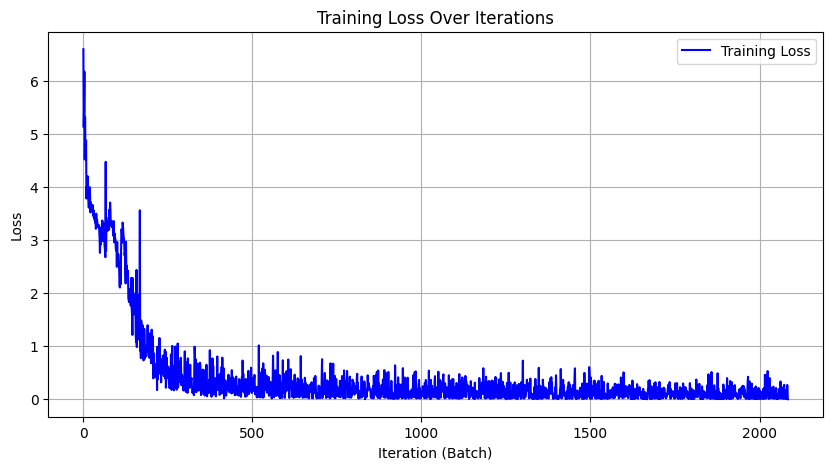

In [11]:
plt.figure(figsize=(10, 5))
plt.plot(losses, label="Training Loss", color="blue")
plt.xlabel("Iteration (Batch)")
plt.ylabel("Loss")
plt.title("Training Loss Over Iterations")
plt.legend()
plt.grid(True)
plt.show()

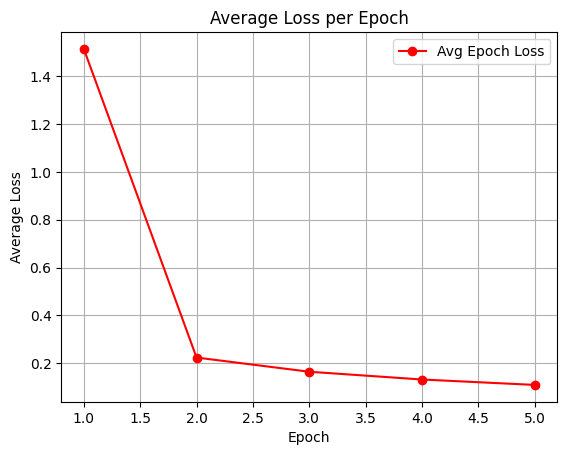

In [12]:
epoch_avg_losses = [sum(losses[i*len(dataloader):(i+1)*len(dataloader)]) / len(dataloader) for i in range(NUM_EPOCHS)]
plt.plot(range(1, NUM_EPOCHS+1), epoch_avg_losses, marker='o', color='red', label="Avg Epoch Loss")
plt.xlabel("Epoch")
plt.ylabel("Average Loss")
plt.title("Average Loss per Epoch")
plt.legend()
plt.grid(True)
plt.show()

## 7. Evaluation

### Load questions.json

In [13]:
with open("questions.json", "r", encoding="utf-8") as f:
    eval_questions = json.load(f)


### (a) TF-IDF Retrieval

In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np

vectorizer = TfidfVectorizer()
tfidf_texts = vectorizer.fit_transform(texts)

def retrieve_tfidf(query, top_k=3):
    q_vec = vectorizer.transform([query])
    scores = (q_vec @ tfidf_texts.T).toarray()[0]
    top_idx = np.argsort(scores)[::-1][:top_k]
    return [texts[i] for i in top_idx]


### (b) Zero-Shot GLOT500 & (c) Fine-tuned GLOT500

In [15]:
def encode_texts(model, data):
    encs = []
    for d in data:
        tok = tokenizer(d, return_tensors="pt", truncation=True, padding="max_length", max_length=MAX_LENGTH).to("cuda")
        with torch.no_grad():
            emb = model(tok["input_ids"], tok["attention_mask"])
        encs.append(emb.cpu())
    return torch.stack(encs).squeeze()

# Zero-shot embeddings
base_encoder = DualEncoder(model_name).cuda().eval()
base_text_embs = encode_texts(base_encoder, texts)

# Fine-tuned embeddings
model.eval()
# model.load_state_dict(torch.load("glot500_finetuned.pth"))
ft_text_embs = encode_texts(model, texts)

def retrieve_nn(query, encoder, text_embs, top_k=3):
    tok = tokenizer(query, return_tensors="pt", truncation=True, padding="max_length", max_length=256).to("cuda")
    with torch.no_grad():
        q_emb = encoder(tok["input_ids"], tok["attention_mask"]).cpu()
    sims = F.cosine_similarity(q_emb, text_embs)
    top_idx = torch.topk(sims, top_k).indices
    return [texts[i] for i in top_idx]


### Run All Models

In [16]:
results = {}

for q_item in eval_questions:
    question_text = q_item["question"]
    results[question_text] = {
        "tfidf": retrieve_tfidf(question_text),
        "glot500_zero_shot": retrieve_nn(question_text, base_encoder, base_text_embs),
        "glot500_finetuned": retrieve_nn(question_text, model, ft_text_embs)
    }

In [17]:
import json
with open("retrieval_results.json", "w", encoding="utf-8") as f:
    json.dump(results, f, ensure_ascii=False, indent=4)

## 8. print the results

In [18]:
for question, result in results.items():
    print(f"question: {question}")
    print("tf-idf:")
    for j in range(len(result['tfidf'])):
        print(f"{j+1}. {result['tfidf'][j]}")
    print("glot500_zero_shot:")
    for j in range(len(result['glot500_zero_shot'])):
        print(f"{j+1}. {result['glot500_zero_shot'][j]}")
    print("glot500_finetuned:")
    for j in range(len(result['glot500_finetuned'])):
        print(f"{j+1}. {result['glot500_finetuned'][j]}")
    print("-"*50)

question: مصطفی کتیرایی در چه شهری درگذشت؟
tf-idf:
1. مصطفی کتیرایی سیاستمدار و وکیل بود. او در تاریخ ۱ فروردین ۱۳۰۷ در ملایر، همدان متولد شد. کتیرایی در تاریخ ۱۲ اسفند ۱۳94 در تهران درگذشت.
2. مصطفی هاشمی مرد و در رشته بسکتبال فعالیت می‌کند.
3. مصطفی مهدوی مردی است که در ایران متولد شده و در رشته ورزشی فوتبال فعالیت می‌کند.
glot500_zero_shot:
1. مرتضی نیک نژاد در تاریخ ۱۳۲۱/۰۵/۰۴ در شهر تهران، استان تهران متولد شد. او در تاریخ ۱۳۴۴/۰۵/۰۴ درگذشت. مرتضی نیک نژاد عضو ائتلاف اسلامی بود.
2. سید مرتضی پسندیده در تاریخ ۱۸۹۶-۰۱-۰۴ در شهر خمین استان مرکزی متولد شد. او در تاریخ ۱۹۹۶-۱۲-۱۱ درگذشت. سید مرتضی پسندیده روحانی، فقیه شیعه و وکیل شرعی بود.
3. مصطفی آجورلو در سال ۱۳۳۹ در تهران متولد شد. او در رشته فوتبال فعالیت می‌کند.
glot500_finetuned:
1. مصطفی کتیرایی سیاستمدار و وکیل بود. او در تاریخ ۱ فروردین ۱۳۰۷ در ملایر، همدان متولد شد. کتیرایی در تاریخ ۱۲ اسفند ۱۳94 در تهران درگذشت.
2. حسابی نطنزی در حوزه گلستان و بوستان فعالیت داشته است.
3. مصطفی سیفی در ۲۲ اکتبر ۱۹۸۵ در قزوین، ایران متولد شد.

## 9. Zip the results and make them ready for download


In [19]:
!zip retrieval_results.zip retrieval_results.json

  adding: retrieval_results.json (deflated 87%)


# Phase 7 - BONUS SECTION: Duplicate Detection with Fine-tuned GLOT500 Model

In [20]:
"""
This bonus implementation demonstrates how to use the fine-tuned GLOT500 model
for duplicate detection in the Persian text dataset. We'll identify semantically
similar texts that might be duplicates or near-duplicates.
"""

import torch
import torch.nn.functional as F
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import DBSCAN
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import json

## 1. DUPLICATE DETECTION SETUP

In [21]:
print("="*60)
print("BONUS: DUPLICATE DETECTION WITH FINE-TUNED GLOT500")
print("="*60)

# Ensure model is loaded and in evaluation mode
model.eval()

def encode_texts_batch(model, texts, batch_size=64):
    """
    Encode texts in batches to handle memory efficiently
    """
    all_embeddings = []

    for i in tqdm(range(0, len(texts), batch_size), desc="Encoding texts"):
        batch_texts = texts[i:i+batch_size]
        batch_embeddings = []

        for text in batch_texts:
            tok = tokenizer(text, return_tensors="pt", truncation=True,
                          padding="max_length", max_length=MAX_LENGTH).to("cuda")
            with torch.no_grad():
                emb = model(tok["input_ids"], tok["attention_mask"])
                batch_embeddings.append(emb.cpu().numpy().flatten())

        all_embeddings.extend(batch_embeddings)

    return np.array(all_embeddings)

print(f"Encoding {len(texts)} texts using fine-tuned model...")
text_embeddings = encode_texts_batch(model, texts)
print(f"Generated embeddings shape: {text_embeddings.shape}")

BONUS: DUPLICATE DETECTION WITH FINE-TUNED GLOT500
Encoding 2666 texts using fine-tuned model...


Encoding texts:   0%|          | 0/42 [00:00<?, ?it/s]/usr/local/lib/python3.11/dist-packages/torch/nn/modules/module.py:1750: FutureWarning: `encoder_attention_mask` is deprecated and will be removed in version 4.55.0 for `XLMRobertaSdpaSelfAttention.forward`.
  return forward_call(*args, **kwargs)
Encoding texts: 100%|██████████| 42/42 [00:35<00:00,  1.18it/s]

Generated embeddings shape: (2666, 256)


## 2. SIMILARITY MATRIX COMPUTATION

In [22]:
print("\nComputing pairwise similarities...")
similarity_matrix = cosine_similarity(text_embeddings)
print(f"Similarity matrix shape: {similarity_matrix.shape}")

# Set diagonal to 0 to ignore self-similarities
np.fill_diagonal(similarity_matrix, 0)


Computing pairwise similarities...
Similarity matrix shape: (2666, 2666)


## 3. STATISTICAL ANALYSIS OF SIMILARITIES

In [23]:
# Get upper triangle of similarity matrix (avoid double counting)
upper_triangle = np.triu(similarity_matrix, k=1)
non_zero_similarities = upper_triangle[upper_triangle > 0]

print(f"\nSimilarity Statistics:")
print(f"Mean similarity: {non_zero_similarities.mean():.4f}")
print(f"Std similarity: {non_zero_similarities.std():.4f}")
print(f"Min similarity: {non_zero_similarities.min():.4f}")
print(f"Max similarity: {non_zero_similarities.max():.4f}")
print(f"95th percentile: {np.percentile(non_zero_similarities, 95):.4f}")
print(f"99th percentile: {np.percentile(non_zero_similarities, 99):.4f}")


Similarity Statistics:
Mean similarity: 0.2228
Std similarity: 0.1310
Min similarity: 0.0000
Max similarity: 1.0000
95th percentile: 0.4545
99th percentile: 0.5546


## 4. VISUALIZATION OF SIMILARITY DISTRIBUTION

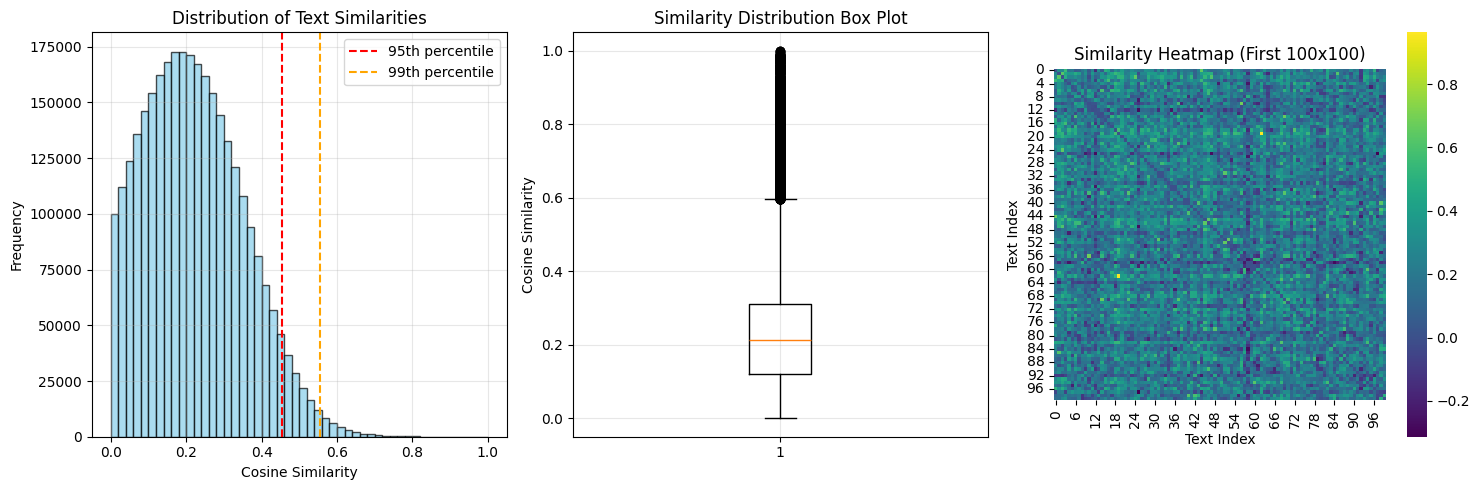

In [24]:
plt.figure(figsize=(15, 5))

# Plot 1: Histogram of similarities
plt.subplot(1, 3, 1)
plt.hist(non_zero_similarities, bins=50, alpha=0.7, color='skyblue', edgecolor='black')
plt.axvline(np.percentile(non_zero_similarities, 95), color='red', linestyle='--',
           label='95th percentile')
plt.axvline(np.percentile(non_zero_similarities, 99), color='orange', linestyle='--',
           label='99th percentile')
plt.xlabel('Cosine Similarity')
plt.ylabel('Frequency')
plt.title('Distribution of Text Similarities')
plt.legend()
plt.grid(True, alpha=0.3)

# Plot 2: Box plot
plt.subplot(1, 3, 2)
plt.boxplot(non_zero_similarities)
plt.ylabel('Cosine Similarity')
plt.title('Similarity Distribution Box Plot')
plt.grid(True, alpha=0.3)

# Plot 3: Heatmap of similarity matrix (sample)
plt.subplot(1, 3, 3)
sample_size = min(100, len(texts))  # Show first 100x100 for visualization
sample_sim = similarity_matrix[:sample_size, :sample_size]
sns.heatmap(sample_sim, cmap='viridis', square=True, cbar=True)
plt.title(f'Similarity Heatmap (First {sample_size}x{sample_size})')
plt.xlabel('Text Index')
plt.ylabel('Text Index')

plt.tight_layout()
plt.show()

## 5. DUPLICATE DETECTION WITH MULTIPLE THRESHOLDS

In [25]:
def find_duplicates_threshold(similarity_matrix, threshold=0.9):
    """
    Find duplicate pairs using similarity threshold
    """
    duplicates = []
    rows, cols = np.where(similarity_matrix >= threshold)

    for i, j in zip(rows, cols):
        if i < j:  # Avoid duplicate pairs (i,j) and (j,i)
            duplicates.append((i, j, similarity_matrix[i, j]))

    return duplicates

# Test different thresholds
thresholds = [0.95, 0.90, 0.85, 0.80, 0.75]
threshold_results = {}

print(f"\n{'='*60}")
print("DUPLICATE DETECTION RESULTS")
print(f"{'='*60}")

for threshold in thresholds:
    duplicates = find_duplicates_threshold(similarity_matrix, threshold)
    threshold_results[threshold] = duplicates
    print(f"Threshold {threshold}: Found {len(duplicates)} duplicate pairs")


DUPLICATE DETECTION RESULTS
Threshold 0.95: Found 72 duplicate pairs
Threshold 0.9: Found 169 duplicate pairs
Threshold 0.85: Found 296 duplicate pairs
Threshold 0.8: Found 538 duplicate pairs
Threshold 0.75: Found 1051 duplicate pairs


## 6. DETAILED ANALYSIS OF HIGH-SIMILARITY PAIRS

In [26]:
# Use 0.85 as our main threshold for detailed analysis
main_threshold = 0.85
main_duplicates = threshold_results[main_threshold]

print(f"\n{'='*60}")
print(f"DETAILED ANALYSIS (Threshold = {main_threshold})")
print(f"{'='*60}")

if main_duplicates:
    # Sort by similarity score (descending)
    main_duplicates.sort(key=lambda x: x[2], reverse=True)

    print(f"\nTop 10 most similar pairs:")
    print("-" * 80)

    for idx, (i, j, sim) in enumerate(main_duplicates[:10]):
        print(f"\nPair {idx+1}: Similarity = {sim:.4f}")
        print(f"Text {i}: {texts[i][:100]}...")
        print(f"Text {j}: {texts[j][:100]}...")
        print("-" * 80)

    # Analyze duplicate distribution
    duplicate_indices = set()
    for i, j, _ in main_duplicates:
        duplicate_indices.add(i)
        duplicate_indices.add(j)

    print(f"\nDuplicate Analysis Summary:")
    print(f"Total unique texts involved in duplicates: {len(duplicate_indices)}")
    print(f"Percentage of dataset with duplicates: {len(duplicate_indices)/len(texts)*100:.2f}%")

else:
    print(f"No duplicates found at threshold {main_threshold}")


DETAILED ANALYSIS (Threshold = 0.85)

Top 10 most similar pairs:
--------------------------------------------------------------------------------

Pair 1: Similarity = 1.0000
Text 260: این یک ورودی نامعتبر است. لطفاً یک ساختار JSON معتبر با اطلاعات مربوط به یک شخص مشهور ارائه دهید....
Text 2069: این یک ورودی نامعتبر است. لطفاً یک ساختار JSON معتبر با اطلاعات مربوط به یک شخص مشهور ارائه دهید....
--------------------------------------------------------------------------------

Pair 2: Similarity = 1.0000
Text 1888: غلامرضا مومنی مقدم در تاریخ ۳ اردیبهشت ۱۳۵۷ متولد شده است. او مرد و در رشته والیبال فعالیت می‌کند. ق...
Text 2551: غلامرضا مومنی مقدم در تاریخ ۳ اردیبهشت ۱۳۵۷ متولد شده است. او مرد و در رشته والیبال فعالیت می‌کند. ق...
--------------------------------------------------------------------------------

Pair 3: Similarity = 0.9986
Text 885: تیم ملی فوتبال زیر ۱۹ سال زنان ایران در رشته ورزشی فوتبال فعالیت می‌کند....
Text 1784: تیم ملی فوتبال زیر ۱۷ سال زنان ایران در رشته ورزشی فوت

## 7. CLUSTERING-BASED DUPLICATE DETECTION

In [27]:
print(f"\n{'='*60}")
print("CLUSTERING-BASED DUPLICATE DETECTION")
print(f"{'='*60}")

# Use DBSCAN clustering to find groups of similar texts
# Convert similarities to distances (1 - similarity)
distance_matrix = 1 - similarity_matrix

# Apply DBSCAN
eps_values = [0.10, 0.15, 0.20]  # These correspond to similarity thresholds of 0.90, 0.85, 0.80
clustering_results = {}

for eps in eps_values:
    print(f"\nClustering with eps={eps} (similarity threshold ≈ {1-eps:.2f})")

    # DBSCAN clustering
    dbscan = DBSCAN(eps=eps, min_samples=2, metric='precomputed')
    clusters = dbscan.fit_predict(distance_matrix)

    # Analyze clusters
    unique_clusters = np.unique(clusters)
    n_clusters = len(unique_clusters) - (1 if -1 in clusters else 0)  # -1 is noise
    n_noise = list(clusters).count(-1)

    print(f"Number of clusters: {n_clusters}")
    print(f"Number of noise points: {n_noise}")

    # Store results
    clustering_results[eps] = clusters

    # Show cluster sizes
    if n_clusters > 0:
        cluster_sizes = {}
        for cluster_id in unique_clusters:
            if cluster_id != -1:  # Skip noise
                cluster_sizes[cluster_id] = list(clusters).count(cluster_id)

        print(f"Cluster sizes: {sorted(cluster_sizes.values(), reverse=True)[:10]}")  # Top 10



CLUSTERING-BASED DUPLICATE DETECTION

Clustering with eps=0.1 (similarity threshold ≈ 0.90)
Number of clusters: 8
Number of noise points: 2618
Cluster sizes: [18, 10, 4, 4, 3, 3, 3, 3]

Clustering with eps=0.15 (similarity threshold ≈ 0.85)
Number of clusters: 12
Number of noise points: 2592
Cluster sizes: [18, 15, 10, 5, 4, 4, 3, 3, 3, 3]

Clustering with eps=0.2 (similarity threshold ≈ 0.80)
Number of clusters: 33
Number of noise points: 2487
Cluster sizes: [25, 20, 12, 7, 7, 7, 6, 6, 6, 6]


## 8. DETAILED CLUSTER ANALYSIS

In [28]:
# Use eps=0.15 for detailed analysis
best_eps = 0.15
best_clusters = clustering_results[best_eps]

print(f"\n{'='*60}")
print(f"DETAILED CLUSTER ANALYSIS (eps={best_eps})")
print(f"{'='*60}")

# Group texts by cluster
cluster_groups = {}
for idx, cluster_id in enumerate(best_clusters):
    if cluster_id != -1:  # Skip noise
        if cluster_id not in cluster_groups:
            cluster_groups[cluster_id] = []
        cluster_groups[cluster_id].append(idx)

# Show largest clusters
if cluster_groups:
    sorted_clusters = sorted(cluster_groups.items(), key=lambda x: len(x[1]), reverse=True)

    print(f"Found {len(sorted_clusters)} clusters")
    print(f"Largest 5 clusters:")

    for cluster_id, text_indices in sorted_clusters[:5]:
        print(f"\nCluster {cluster_id} (size: {len(text_indices)}):")
        print("-" * 40)

        for i, text_idx in enumerate(text_indices[:3]):  # Show first 3 texts
            print(f"  {i+1}. {texts[text_idx][:80]}...")

        if len(text_indices) > 3:
            print(f"  ... and {len(text_indices) - 3} more texts")


DETAILED CLUSTER ANALYSIS (eps=0.15)
Found 12 clusters
Largest 5 clusters:

Cluster 3 (size: 18):
----------------------------------------
  1. این یک فهرست از مربیان برنده لیگ فوتبال ایران است. در این فهرست، جنسیت مربیان مر...
  2. این یک فهرست از مربیان تیم ملی فوتبال ایران است. جنسیت مربیان مرد است و ورزش آن‌...
  3. این یک فهرست از بازیکنان ملی‌پوش فوتبال مرد ایرانی است که تابعیت دوگانه دارند....
  ... and 15 more texts

Cluster 1 (size: 15):
----------------------------------------
  1. باشگاه فوتبال زنان همیاری ارومیه یک باشگاه ورزشی زنانه است که در رشته فوتبال فعا...
  2. باشگاه فوتبال زنان ملوان بندر انزلی یک باشگاه فوتبال زنانه است....
  3. باشگاه فوتبال ملوان بندر انزلی یک باشگاه فوتبال مردانه است....
  ... and 12 more texts

Cluster 4 (size: 10):
----------------------------------------
  1. لیگ برتر فوتبال زنان ایران ۰۳–۱۴۰۲ یک رقابت ورزشی در رشته فوتبال است که ویژه بان...
  2. لیگ دسته اول فوتبال زنان ایران ۰۴–۱۴۰۳ یک رقابت ورزشی در رشته فوتبال است که ویژه...
  3. لیگ برت

## 9. EXPORT DUPLICATE DETECTION RESULTS

In [29]:
print(f"\n{'='*60}")
print("EXPORTING RESULTS")
print(f"{'='*60}")

# Prepare results for export
export_results = {
    "similarity_statistics": {
        "mean_similarity": float(non_zero_similarities.mean()),
        "std_similarity": float(non_zero_similarities.std()),
        "min_similarity": float(non_zero_similarities.min()),
        "max_similarity": float(non_zero_similarities.max()),
        "percentile_95": float(np.percentile(non_zero_similarities, 95)),
        "percentile_99": float(np.percentile(non_zero_similarities, 99))
    },
    "threshold_based_duplicates": {},
    "clustering_results": {},
    "detailed_duplicate_pairs": []
}

# Add threshold results
for threshold, duplicates in threshold_results.items():
    export_results["threshold_based_duplicates"][str(threshold)] = {
        "count": len(duplicates),
        "pairs": [(int(i), int(j), float(sim)) for i, j, sim in duplicates[:50]]  # Top 50
    }

# Add clustering results
for eps, clusters in clustering_results.items():
    unique_clusters = np.unique(clusters)
    n_clusters = len(unique_clusters) - (1 if -1 in clusters else 0)
    export_results["clustering_results"][str(eps)] = {
        "n_clusters": int(n_clusters),
        "n_noise": int(list(clusters).count(-1))
    }

# Add detailed pairs from main threshold
for i, j, sim in main_duplicates[:20]:  # Top 20 pairs
    export_results["detailed_duplicate_pairs"].append({
        "text_index_1": int(i),
        "text_index_2": int(j),
        "similarity_score": float(sim),
        "text_1_preview": texts[i][:100],
        "text_2_preview": texts[j][:100]
    })

# Save results
with open("duplicate_detection_results.json", "w", encoding="utf-8") as f:
    json.dump(export_results, f, ensure_ascii=False, indent=4)

print("Results exported to 'duplicate_detection_results.json'")


EXPORTING RESULTS
Results exported to 'duplicate_detection_results.json'


## 10. SUMMARY STATISTICS AND RECOMMENDATIONS

In [32]:
print(f"\n{'='*60}")
print("DUPLICATE DETECTION SUMMARY")
print(f"{'='*60}")

print(f"Dataset Summary:")
print(f"  - Total texts analyzed: {len(texts)}")
print(f"  - Embedding dimension: {text_embeddings.shape[1]}")
print(f"  - Average similarity: {non_zero_similarities.mean():.4f}")

print(f"\nKey Findings:")
if main_duplicates:
    duplicate_indices = set()
    for i, j, _ in main_duplicates:
        duplicate_indices.add(i)
        duplicate_indices.add(j)

    print(f"  - Potential duplicates at {main_threshold} threshold: {len(main_duplicates)} pairs")
    print(f"  - Texts involved in duplicates: {len(duplicate_indices)} ({len(duplicate_indices)/len(texts)*100:.1f}%)")
    print(f"  - Highest similarity found: {max(sim for _, _, sim in main_duplicates):.4f}")
else:
    print(f"  - No clear duplicates detected at threshold {main_threshold}")

print(f"\nClustering Results (eps={best_eps}):")
if cluster_groups:
    print(f"  - Number of clusters: {len(cluster_groups)}")
    print(f"  - Largest cluster size: {max(len(indices) for indices in cluster_groups.values())}")
else:
    print(f"  - No significant clusters found")

print(f"\n{'='*60}")
print("BONUS DUPLICATE DETECTION COMPLETED!")
print(f"{'='*60}")


DUPLICATE DETECTION SUMMARY
Dataset Summary:
  - Total texts analyzed: 2666
  - Embedding dimension: 256
  - Average similarity: 0.2228

Key Findings:
  - Potential duplicates at 0.85 threshold: 296 pairs
  - Texts involved in duplicates: 252 (9.5%)
  - Highest similarity found: 1.0000

Clustering Results (eps=0.15):
  - Number of clusters: 12
  - Largest cluster size: 18

BONUS DUPLICATE DETECTION COMPLETED!


## 11. CREATE VISUALIZATION OF DUPLICATE NETWORK


Creating duplicate network visualization...


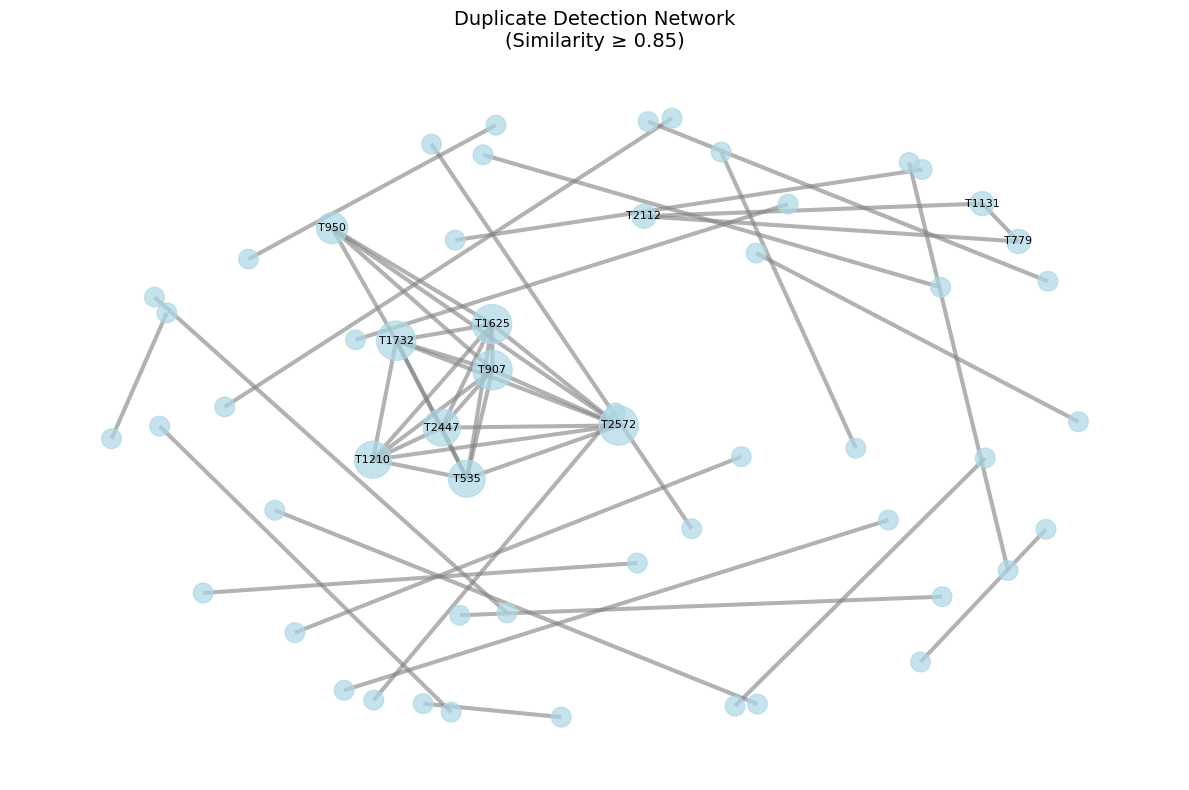

Network contains 55 texts and 50 duplicate relationships

🎉 Bonus section completed successfully! 🎉


In [ ]:
try:
    import networkx as nx

    print(f"\nCreating duplicate network visualization...")

    # Create network graph for duplicates
    G = nx.Graph()

    # Add edges for duplicate pairs (using main threshold)
    for i, j, sim in main_duplicates[:50]:  # Limit to top 50 for readability
        G.add_edge(i, j, weight=sim)

    if len(G.nodes()) > 0:
        plt.figure(figsize=(12, 8))

        # Layout
        pos = nx.spring_layout(G, k=1, iterations=50)

        # Draw network
        nx.draw_networkx_nodes(G, pos, node_color='lightblue',
                              node_size=[G.degree(node) * 100 + 100 for node in G.nodes()],
                              alpha=0.7)

        edges = G.edges(data=True)
        nx.draw_networkx_edges(G, pos,
                              edgelist=[(u, v) for u, v, d in edges],
                              width=[d['weight'] * 3 for u, v, d in edges],
                              alpha=0.6, edge_color='gray')

        # Add labels for nodes with high connectivity
        high_degree_nodes = [node for node in G.nodes() if G.degree(node) >= 2]
        labels = {node: f"T{node}" for node in high_degree_nodes}
        nx.draw_networkx_labels(G, pos, labels, font_size=8)

        plt.title(f'Duplicate Detection Network\n(Similarity ≥ {main_threshold})', fontsize=14)
        plt.axis('off')
        plt.tight_layout()
        plt.show()

        print(f"Network contains {len(G.nodes())} texts and {len(G.edges())} duplicate relationships")
    else:
        print("No duplicate network to visualize (no duplicates found)")

except ImportError:
    print("NetworkX not available for network visualization")

print("\n 🎉 Bonus section completed successfully! 🎉")